# ITESO, Universidad Jesuita de Guadalajara

**Materia:** Análisis Estadístico Multivariable

**Profesor:** Luis Alvarado

**Actividad:** Proyecto: RSNA Knee Abnormality Detection (Kaggle). Notebook 1 de 2: trayecto

**Integrante:** Lambda Remiel Heredia Pérez (Kaggle: `hctorheredia`, GitHub: `RemiH06`)

**Fecha:** 15 de octubre de 2026

---

## Introducción

La competencia [RSNA Knee Abnormality Detection](https://www.kaggle.com/competitions/rsna-knee-abnormality-detection) pide, para cada estudio de resonancia magnética (MRI) de rodilla, la probabilidad de 12 hallazgos clínicos: ruptura de ligamento cruzado anterior (ACL) y colateral medial (MCL), lesión de menisco medial y lateral, osteoartritis medial, lateral y patelofemoral (OA), derrame articular, sinovitis, quiste de Baker, contusión ósea y fractura.

Cada estudio es entonces una observación de un **vector aleatorio** $\mathbf{Y}=(Y_1,\dots,Y_{12})^\top$ con $Y_k\in\{0,1\}$: una Bernoulli multivariada. Los hallazgos no son independientes entre sí (una rodilla con artrosis medial suele tener también el menisco medial dañado), y ese es justo el terreno de la materia: vector de medias, matriz de covarianza y correlación, distribuciones conjuntas, marginales y condicionales, pruebas de independencia, máxima verosimilitud y razón de verosimilitudes.

Este notebook documenta el trayecto completo, fase por fase, como se planeó en `steps.md`. El segundo notebook (`02_version_definitiva.ipynb`) es el que genera el envío final en Kaggle.

**Nota de honestidad.** El modelo de imagen y su preprocesamiento adaptan trabajo público de la comunidad (notebooks de `dreaddevelopment`, Apache 2.0) y las etiquetas derivadas de los reportes son un dataset público (`stevenleehans`, CC0). La aportación propia es el reentrenamiento con un corpus regenerado desde los 265 GB originales, la validación estadística y la combinación final. El objetivo de este notebook es llegar, con análisis propio, a las mismas conclusiones que la comunidad y justificarlas con estadística.

### Métrica

Para cada hallazgo $k$ se calcula el área bajo la curva ROC y se promedian las 12:

$$\text{Score}=\frac{1}{12}\sum_{k=1}^{12}\text{AUC}_k$$

El AUC tiene una lectura probabilística directa: si $S^{+}$ es la puntuación de un estudio positivo y $S^{-}$ la de uno negativo, elegidos al azar,

$$\text{AUC}=P\left(S^{+}>S^{-}\right)+\tfrac12P\left(S^{+}=S^{-}\right),$$

que se estima con el estadístico de Mann-Whitney $\widehat{\text{AUC}}=U/(n_1n_0)$. Consecuencia práctica que se usa al final: el AUC solo depende del **orden** de las puntuaciones, así que es invariante ante cualquier transformación monótona creciente.

In [1]:
from pathlib import Path
import json, re, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=RuntimeWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RES = ROOT / "data", ROOT / "results"

T = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
     "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
ES = dict(zip(T, ["LCA", "LCM", "Menisco med.", "Menisco lat.", "OA medial", "OA lateral",
                  "OA patelofem.", "Derrame", "Sinovitis", "Q. Baker", "Contusión", "Fractura"]))

# Paleta: azul / naranja / aqua (categórica, orden fijo); divergente azul-gris-rojo; secuencial azul.
AZUL, NARANJA, AQUA, ROJO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#898781"
DIV = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold"})

tr = pd.read_csv(DATA / "train.csv")
se = pd.read_csv(DATA / "train_series.csv")
gold = tr.dropna(subset=T).set_index("StudyInstanceUID")[T].astype(int)
print(f"train.csv: {len(tr):,} estudios | con las 12 etiquetas (gold): {len(gold)} | "
      f"train_series.csv: {len(se):,} series")

train.csv: 4,407 estudios | con las 12 etiquetas (gold): 58 | train_series.csv: 24,371 series


## Fase 0. Datos disponibles

| Archivo | Contenido | Tamaño |
|---|---|---|
| `train.csv` | 4,407 estudios: reporte de radiología (texto libre) y 12 etiquetas | solo **58** estudios traen las 12 etiquetas |
| `train_series.csv` | 24,371 series: plano anatómico, sensible a fluido, supresión de grasa | 5.5 series por estudio |
| `train_series/` | 819,078 cortes DICOM | 265 GB comprimidos, 569 GB descomprimidos |
| `test.csv` | ~1,300 estudios ocultos al calificar | **sin reporte** |

Dos hechos definen todo el proyecto:

1. **Supervisión débil.** El 98.7 % de los estudios no tiene etiqueta. Lo que sí tienen todos es el reporte del radiólogo, que menciona los hallazgos en texto.
2. **El reporte no existe en test.** El modelo final solo puede ver la imagen. El texto sirve para fabricar etiquetas de entrenamiento, no como entrada.

De ahí sale la estrategia (la misma a la que llegó la comunidad): leer cada reporte con un modelo de lenguaje y convertirlo en una probabilidad por hallazgo (etiqueta suave), entrenar un modelo de imagen contra esas etiquetas, y reservar los 58 estudios gold **solo para validar**.

## Fase 1. Análisis exploratorio

### 1.1 Vector de medias: prevalencia de cada hallazgo

Para un hallazgo $Y_k\sim\text{Bernoulli}(p_k)$ y una muestra $y_{1k},\dots,y_{nk}$, la verosimilitud es

$$L(p_k)=\prod_{i=1}^{n}p_k^{\,y_{ik}}(1-p_k)^{1-y_{ik}},\qquad \ell(p_k)=\Big(\sum_i y_{ik}\Big)\ln p_k+\Big(n-\sum_i y_{ik}\Big)\ln(1-p_k).$$

Igualando a cero, $\ell'(p_k)=\dfrac{\sum y_{ik}}{p_k}-\dfrac{n-\sum y_{ik}}{1-p_k}=0\Rightarrow \hat p_k=\bar y_k$, y $\ell''<0$ confirma el máximo. El estimador de máxima verosimilitud del vector de prevalencias es el **vector de medias muestral** $\bar{\mathbf y}$. Con $n=58$ la incertidumbre es grande; se reporta el intervalo de Wilson al 95 %, que se porta mejor que el de Wald con muestras chicas.

,positivos,p_hat,IC95_inf,IC95_sup
LCM,9,0.155,0.084,0.269
OA lateral,11,0.190,0.109,0.309
Q. Baker,12,0.207,0.123,0.328
OA medial,15,0.259,0.163,0.384
Fractura,18,0.310,0.206,0.438
Contusión,19,0.328,0.221,0.456
OA patelofem.,21,0.362,0.251,0.491
Menisco lat.,23,0.397,0.281,0.525
LCA,24,0.414,0.296,0.542
Menisco med.,26,0.448,0.327,0.575


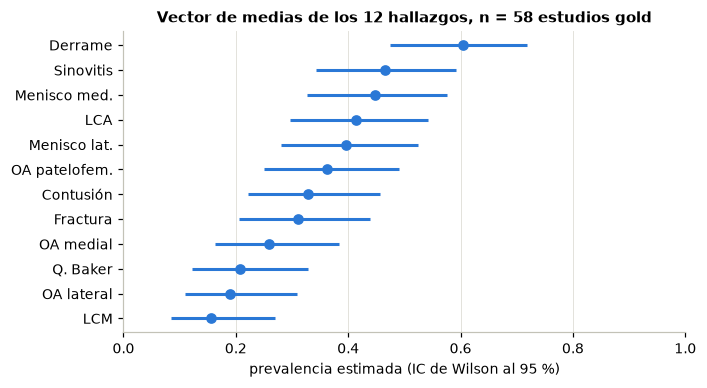

In [2]:
n = len(gold)
p_hat = gold.mean()
lo, hi = proportion_confint(gold.sum(), n, alpha=0.05, method="wilson")
prev = pd.DataFrame({"positivos": gold.sum(), "p_hat": p_hat, "IC95_inf": lo, "IC95_sup": hi},
                    index=T).rename(index=ES).sort_values("p_hat")
display(prev.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.errorbar(prev.p_hat, range(len(prev)), xerr=[prev.p_hat - prev.IC95_inf, prev.IC95_sup - prev.p_hat],
            fmt="o", color=AZUL, ms=6, elinewidth=2, capsize=0)
ax.set_yticks(range(len(prev)), prev.index); ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_xlabel("prevalencia estimada (IC de Wilson al 95 %)")
ax.set_title(f"Vector de medias de los 12 hallazgos, n = {n} estudios gold")
plt.tight_layout(); plt.show()

**Interpretación.** Los hallazgos no son raros en esta muestra: van del 16 % (LCM) al 60 % (derrame). Los intervalos miden entre 18 y 25 puntos porcentuales: con 58 estudios la prevalencia de cada hallazgo apenas se conoce. Además la competencia advierte que la prevalencia puede cambiar entre entrenamiento, leaderboard público y evaluación final. Esto es una ventaja de usar AUC: al depender solo del orden de las puntuaciones, no se afecta por un cambio de prevalencia, mientras que métricas como la exactitud sí.

### 1.2 Matriz de covarianza y de correlación

Con $\mathbf y_i\in\{0,1\}^{12}$, la matriz de covarianza muestral es

$$\mathbf S=\frac{1}{n-1}\sum_{i=1}^{n}(\mathbf y_i-\bar{\mathbf y})(\mathbf y_i-\bar{\mathbf y})^\top,\qquad \mathbf R=\mathbf D^{-1/2}\,\mathbf S\,\mathbf D^{-1/2},\quad \mathbf D=\operatorname{diag}(\mathbf S).$$

Para dos variables binarias, la correlación de Pearson es el **coeficiente $\phi$** de la tabla 2×2. La diagonal de $\mathbf S$ son las varianzas $s_{kk}=\tfrac{n}{n-1}\hat p_k(1-\hat p_k)$.

Traza de S (varianza total): 2.567
Varianzas s_kk: [0.247 0.133 0.252 0.243 0.195 0.156 0.235 0.243 0.253 0.167 0.224 0.218]


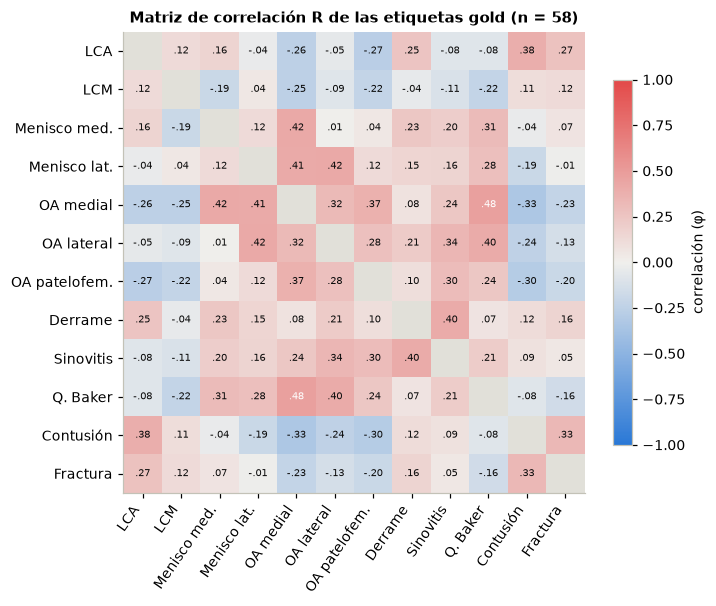

,hallazgo_1,hallazgo_2,phi
0,OA medial,Q. Baker,0.476
1,Menisco med.,OA medial,0.418
2,Menisco lat.,OA lateral,0.417
3,Menisco lat.,OA medial,0.407
4,OA lateral,Q. Baker,0.404
5,Derrame,Sinovitis,0.403
6,LCA,Contusión,0.383
7,OA medial,OA patelofem.,0.374


In [3]:
S = gold.cov()
R = gold.corr()
print("Traza de S (varianza total):", round(np.trace(S), 3))
print("Varianzas s_kk:", S.values.diagonal().round(3))

fig, ax = plt.subplots(figsize=(6.6, 5.6))
Rm = R.values.copy(); np.fill_diagonal(Rm, np.nan)
im = ax.imshow(np.ma.masked_invalid(Rm), cmap=DIV, vmin=-1, vmax=1)
ax.set_facecolor("#e1e0d9")
lab = [ES[t] for t in T]
ax.set_xticks(range(12), lab, rotation=55, ha="right"); ax.set_yticks(range(12), lab); ax.grid(False)
for i in range(12):
    for j in range(12):
        if i != j:
            ax.text(j, i, f"{R.iloc[i, j]:.2f}".replace("0.", "."), ha="center", va="center", fontsize=6.5,
                    color="#0b0b0b" if abs(R.iloc[i, j]) < 0.45 else "white")
fig.colorbar(im, ax=ax, shrink=0.75, label="correlación (φ)")
ax.set_title("Matriz de correlación R de las etiquetas gold (n = 58)")
plt.tight_layout(); plt.show()

iu = np.triu_indices(12, 1)
pares = pd.DataFrame({"hallazgo_1": [ES[T[i]] for i in iu[0]], "hallazgo_2": [ES[T[j]] for j in iu[1]],
                      "phi": R.values[iu]}).sort_values("phi", key=abs, ascending=False)
display(pares.head(8).round(3).reset_index(drop=True))

**Interpretación.** La matriz no es la identidad: hay bloques. Las correlaciones positivas más fuertes (todas entre 0.37 y 0.48) se agrupan en familias con sentido clínico:

- **Degenerativa:** OA medial, lateral y patelofemoral, meniscos y quiste de Baker se acompañan (la artrosis desgasta el menisco y el derrame crónico forma el quiste). El par más fuerte es OA medial y quiste de Baker ($\phi=0.48$).
- **Traumática:** LCA, contusión ósea y fractura se acompañan (un giro brusco de rodilla rompe el ligamento y golpea hueso contra hueso).
- **Inflamatoria:** derrame y sinovitis ($\phi=0.40$), dos formas de líquido e inflamación dentro de la articulación.

Entre la familia degenerativa y la traumática la correlación es **negativa** (OA medial contra contusión, $\phi=-0.33$; contra LCA, $-0.26$): son perfiles de pacientes distintos, el adulto mayor con desgaste y el joven con una lesión deportiva. La sección 1.4 lo confirma con valores propios.

### 1.3 Distribución conjunta de dos hallazgos: LCA y contusión

Se trata el par (LCA, contusión) como el problema 3 del examen: tabla de masa conjunta, marginales, condicionales e independencia. La prueba formal es la **prueba de razón de verosimilitudes** (LRT). Bajo $H_0$ (independencia) el estimador de máxima verosimilitud de cada celda es el producto de marginales, $\hat\pi^{(0)}_{ab}=\hat p_{a\cdot}\,\hat p_{\cdot b}$; bajo $H_1$ (cualquier distribución conjunta) es la frecuencia observada, $\hat\pi^{(1)}_{ab}=O_{ab}/n$. Entonces

$$\Lambda=2\left(\ell_1-\ell_0\right)=2\sum_{a,b}O_{ab}\ln\frac{O_{ab}}{E_{ab}},\qquad E_{ab}=n\,\hat p_{a\cdot}\hat p_{\cdot b},$$

y $\Lambda\sim\chi^2_{(r-1)(c-1)}=\chi^2_1$. Se rechaza $H_0$ si $\Lambda>\chi^2_{1,0.05}=3.84$.

In [4]:
def lrt_indep(tabla):
    # Razón de verosimilitudes para independencia en una tabla de contingencia.
    O = np.asarray(tabla, float); n = O.sum()
    E = np.outer(O.sum(1), O.sum(0)) / n
    m = O > 0
    G = 2 * (O[m] * np.log(O[m] / E[m])).sum()
    gl = (O.shape[0] - 1) * (O.shape[1] - 1)
    return G, gl, stats.chi2.sf(G, gl), E

conj = pd.crosstab(gold["ACL"], gold["Contusion"], margins=True, margins_name="marginal") / n
conj.index.name, conj.columns.name = "LCA", "Contusión"
display(conj.round(3))

p_c1_a1 = conj.loc[1, 1] / conj.loc[1, "marginal"]
p_c1_a0 = conj.loc[0, 1] / conj.loc[0, "marginal"]
print(f"P(Contusión=1 | LCA=1) = {p_c1_a1:.2f}    P(Contusión=1 | LCA=0) = {p_c1_a0:.2f}")
print(f"f(0,0) = {conj.loc[0, 0]:.3f}  vs  f_X(0) f_Y(0) = {conj.loc[0, 'marginal'] * conj.loc['marginal', 0]:.3f}")

O = pd.crosstab(gold["ACL"], gold["Contusion"]).values
G, gl, p, E = lrt_indep(O)
print(f"\nLRT: Λ = {G:.2f}, gl = {gl}, valor crítico = {stats.chi2.ppf(0.95, gl):.2f}, p = {p:.4f}")
print("Frecuencias esperadas bajo H0:\n", E.round(1))
print(f"Prueba exacta de Fisher (control, por n chico): p = {stats.fisher_exact(O)[1]:.4f}")

Contusión,0,1,marginal
LCA,,,
0,0.483,0.103,0.586
1,0.190,0.224,0.414
marginal,0.672,0.328,1.000


P(Contusión=1 | LCA=1) = 0.54    P(Contusión=1 | LCA=0) = 0.18
f(0,0) = 0.483  vs  f_X(0) f_Y(0) = 0.394

LRT: Λ = 8.57, gl = 1, valor crítico = 3.84, p = 0.0034
Frecuencias esperadas bajo H0:
 [[22.9 11.1]
 [16.1  7.9]]
Prueba exacta de Fisher (control, por n chico): p = 0.0049


**Interpretación.** Si la rodilla tiene el LCA roto, la probabilidad de contusión ósea es 0.54, el triple que si no lo tiene (0.18). La celda $(0,0)$ ya no coincide con el producto de marginales, y la LRT supera el valor crítico de 3.84: se **rechaza la independencia** al 5 %. Todas las frecuencias esperadas superan 5 (la menor es 7.9), así que la aproximación $\chi^2$ es razonable; como control, la prueba exacta de Fisher llega a la misma conclusión. Clínicamente es el patrón de "pivot shift": al romperse el LCA la tibia se desplaza y golpea al fémur, dejando la contusión.

### 1.4 Independencia por pares y estructura de la matriz

Se repite la LRT para los $\binom{12}{2}=66$ pares. Con 66 pruebas al 5 % se esperan unos 3 rechazos por azar, así que también se reporta la corrección de Bonferroni ($\alpha=0.05/66$).

In [5]:
rows = []
for i, j in zip(*iu):
    G, gl, p, _ = lrt_indep(pd.crosstab(gold[T[i]], gold[T[j]]).values)
    rows.append((ES[T[i]], ES[T[j]], R.values[i, j], G, p))
lrt = pd.DataFrame(rows, columns=["hallazgo_1", "hallazgo_2", "phi", "Lambda", "p"]).sort_values("Lambda", ascending=False)
lrt["rechaza_5%"] = lrt.p < 0.05
lrt["rechaza_Bonferroni"] = lrt.p < 0.05 / 66
print(f"Pares que rechazan independencia: {lrt['rechaza_5%'].sum()} de 66 al 5 % "
      f"(se esperarían ~3.3 por azar); {lrt['rechaza_Bonferroni'].sum()} con Bonferroni")
display(lrt[lrt["rechaza_5%"]].round(4).reset_index(drop=True))

Pares que rechazan independencia: 23 de 66 al 5 % (se esperarían ~3.3 por azar); 1 con Bonferroni


,hallazgo_1,hallazgo_2,phi,Lambda,p,rechaza_5%,rechaza_Bonferroni
0,OA medial,Q. Baker,0.4760,11.7959,0.0006,True,True
1,Menisco med.,OA medial,0.4177,10.5048,0.0012,True,False
2,Menisco lat.,OA lateral,0.4170,10.2225,0.0014,True,False
3,Derrame,Sinovitis,0.4032,9.8642,0.0017,True,False
4,Menisco lat.,OA medial,0.4066,9.5886,0.0020,True,False
5,LCA,Contusión,0.3832,8.5727,0.0034,True,False
6,OA lateral,Q. Baker,0.4043,8.0806,0.0045,True,False
7,OA medial,OA patelofem.,0.3743,7.9357,0.0048,True,False
8,OA medial,Contusión,-0.3283,7.5510,0.0060,True,False
9,OA lateral,Sinovitis,0.3420,7.1406,0.0075,True,False


Para ver cuántas "direcciones" independientes hay en los 12 hallazgos se descompone $\mathbf R=\mathbf V\boldsymbol\Lambda\mathbf V^\top$. La suma de valores propios es la traza, $\operatorname{tr}(\mathbf R)=12$; si los hallazgos fueran independientes todos los valores propios serían cercanos a 1.

Valores propios: [3.08 1.93 1.23 1.12 0.84 0.78 0.72 0.62 0.55 0.47 0.35 0.3 ] | suma = 12.0
Proporción acumulada: [0.26 0.42 0.52 0.61 0.68]


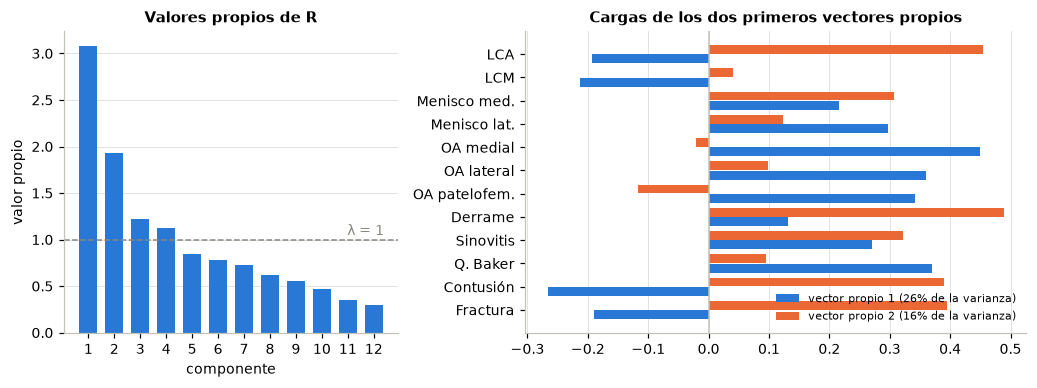

In [6]:
val, vec = np.linalg.eigh(R.values)
orden = np.argsort(val)[::-1]; val, vec = val[orden], vec[:, orden]
print("Valores propios:", val.round(2), "| suma =", val.sum().round(2))
print("Proporción acumulada:", (val.cumsum() / 12).round(2)[:5])

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
axs[0].bar(range(1, 13), val, color=AZUL, width=0.7)
axs[0].axhline(1, color=GRIS, lw=1, ls="--"); axs[0].text(12.4, 1.05, "λ = 1", color=GRIS, ha="right")
axs[0].set_xticks(range(1, 13)); axs[0].set_xlabel("componente"); axs[0].set_ylabel("valor propio")
axs[0].set_title("Valores propios de R"); axs[0].grid(axis="x", visible=False)
for c, (k, col) in enumerate([(0, AZUL), (1, NARANJA)]):
    v = vec[:, k] * np.sign(vec[T.index("Medial OA"), k] if k == 0 else vec[T.index("Contusion"), k])
    axs[1].barh(np.arange(12) + (0.2 if c == 0 else -0.2), v, height=0.38, color=col,
                label=f"vector propio {k + 1} ({val[k] / 12:.0%} de la varianza)")
axs[1].set_yticks(range(12), [ES[t] for t in T]); axs[1].axvline(0, color="#c3c2b7", lw=1)
axs[1].invert_yaxis(); axs[1].legend(loc="lower right", fontsize=7.5, frameon=False)
axs[1].set_title("Cargas de los dos primeros vectores propios"); axs[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Interpretación.** 23 de los 66 pares rechazan la independencia al 5 %, siete veces más de los ~3 esperados por azar: los 12 hallazgos forman un vector **dependiente**. Bonferroni es muy conservador con $n=58$ y solo deja en pie al par OA medial y quiste de Baker, pero el exceso de rechazos ya es evidencia conjunta de dependencia.

Los valores propios lo confirman. Si los hallazgos fueran independientes, todos estarían cerca de 1; en cambio el primero vale 3.08 (26 % de la varianza total) y el segundo 1.93 (16 %).

- El **primer vector propio** es el eje degenerativo contra traumático: cargas positivas en OA (medial, lateral, patelofemoral), meniscos y quiste de Baker; negativas en LCA, LCM, contusión y fractura.
- El **segundo** tiene cargas positivas en derrame, LCA, contusión, fractura, sinovitis y menisco medial: un eje de **lesión aguda** (trauma reciente con líquido en la articulación).

Con 58 estudios conviene no sobreinterpretar los componentes de orden alto, pero la conclusión práctica es clara y respalda la arquitectura del modelo: **un solo modelo con un extractor de rasgos compartido para los 12 hallazgos**, en vez de 12 modelos separados, porque los hallazgos comparten información.

### 1.5 Los reportes de radiología

Los reportes vienen de varios hospitales y en varios idiomas. Se clasifica el idioma con una heurística simple (conteo de palabras funcionales propias de cada idioma); no es perfecta, pero basta para dimensionar el problema.

,estudios,longitud_mediana,%
idioma,,,
inglés,3094,1001.5,70.2
español,681,780.0,15.5
alemán,262,807.0,5.9
neerlandés,191,918.0,4.3
portugués,91,1342.0,2.1
francés,88,1508.5,2.0


[inglés]  In the medial compartment, the meniscus is not torn and there is no focal chondrosis or chondral injury. 
 The lateral compartment, there is suspicious incompl...
[español] Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial me...
[alemán] Regelrechte Artikulationsverhältnisse. Homogenes Knochenmarksignal, kein Knochenödem. Oberflächliche Chondropathie in der Belastungszone der medialen Femurkondy...
[neerlandés] [DATE]: * MR Knie Rechts 15ch AA Klinische Inlichtingen: [DATE]. Diagnostische vraagstellling: Meniscusscheur/mediaal? Scanprotocol (DRB) : sag intermediair gew...


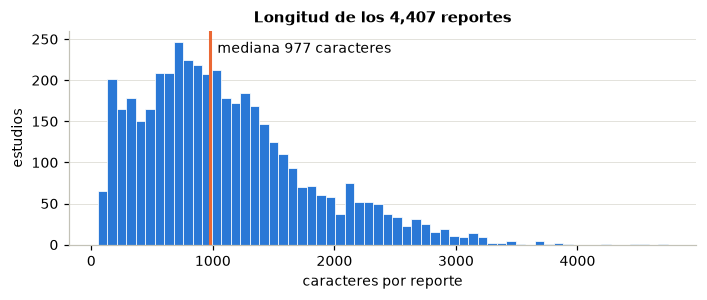

In [7]:
PAL = {"inglés": r"\b(the|and|with|is|of|no|knee|tear|effusion)\b",
       "español": r"\b(el|los|las|con|sin|del|rodilla|rotura|derrame|menisco)\b",
       "alemán": r"\b(der|die|und|mit|kein|keine|ist|knie|erguss|riss)\b",
       "neerlandés": r"\b(het|een|geen|van|met|en|knie|vocht|scheur)\b",
       "portugués": r"\b(não|com|sem|do|da|joelho|rotura|derrame)\b",
       "francés": r"\b(le|les|des|du|une|genou|épanchement|fissure)\b",
       "italiano": r"\b(il|della|senza|ginocchio|versamento|lesione)\b"}
def idioma(s):
    s = s.lower()
    return max(PAL, key=lambda k: len(re.findall(PAL[k], s)))

tr["idioma"] = tr.Report.map(idioma)
tr["longitud"] = tr.Report.str.len()
resumen = tr.groupby("idioma").agg(estudios=("Report", "size"), longitud_mediana=("longitud", "median"))
resumen["%"] = 100 * resumen.estudios / len(tr)
display(resumen.sort_values("estudios", ascending=False).round(1))
for lang in resumen.sort_values("estudios", ascending=False).index[:4]:
    print(f"[{lang}] {tr[tr.idioma == lang].Report.iloc[0][:160]}...")

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.hist(tr.longitud, bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(tr.longitud.median(), color=NARANJA, lw=2)
ax.text(tr.longitud.median() + 60, ax.get_ylim()[1] * 0.9, f"mediana {tr.longitud.median():.0f} caracteres")
ax.set_xlabel("caracteres por reporte"); ax.set_ylabel("estudios"); ax.grid(axis="x", visible=False)
ax.set_title(f"Longitud de los {len(tr):,} reportes")
plt.tight_layout(); plt.show()

**Interpretación.** Hay al menos seis idiomas (70 % inglés, 15 % español, y alemán, neerlandés, portugués y francés en el resto) y la longitud varía de una línea a varias páginas, con cola larga a la derecha. Reglas a mano (buscar "ACL tear") no escalan a esa variedad; por eso la comunidad usó modelos de lenguaje para leer los reportes (Fase 2).

### 1.6 Las series de cada estudio: una distribución conjunta discreta

Cada serie trae tres variables categóricas: plano anatómico (sagital, coronal, axial), si es sensible a fluido y si tiene supresión de grasa. Su tabla conjunta:

In [8]:
print("¿Fluid_Sensitive == Fat_Suppression en todas las series?", (se.Fluid_Sensitive == se.Fat_Suppression).all())
print("Correlación entre ambas:", se[["Fluid_Sensitive", "Fat_Suppression"]].corr().iloc[0, 1])

conj = pd.crosstab(se.Anatomical_Plane, se.Fat_Suppression, margins=True, margins_name="marginal",
                   normalize="all")
conj.columns = ["sin supresión (T1/PD)", "con supresión (FS)", "marginal"]
display(conj.round(3))
cond = pd.crosstab(se.Anatomical_Plane, se.Fat_Suppression, normalize="index")
cond.columns = ["P(sin FS | plano)", "P(FS | plano)"]
display(cond.round(3))
G, gl, p, _ = lrt_indep(pd.crosstab(se.Anatomical_Plane, se.Fat_Suppression).values)
print(f"LRT plano vs supresión: Λ = {G:.1f}, gl = {gl}, crítico = {stats.chi2.ppf(.95, gl):.2f}, p = {p:.2e}")

¿Fluid_Sensitive == Fat_Suppression en todas las series? True
Correlación entre ambas: 1.0


,sin supresión (T1/PD),con supresión (FS),marginal
Anatomical_Plane,,,
Axial,0.048,0.194,0.242
Coronal,0.164,0.190,0.353
Sagittal,0.213,0.191,0.405
marginal,0.425,0.575,1.000


,P(sin FS | plano),P(FS | plano)
Anatomical_Plane,,
Axial,0.200,0.800
Coronal,0.463,0.537
Sagittal,0.527,0.473


LRT plano vs supresión: Λ = 1802.8, gl = 2, crítico = 5.99, p = 0.00e+00


**Interpretación.** Las variables `Fluid_Sensitive` y `Fat_Suppression` valen lo mismo en las 24,371 series: su correlación es exactamente 1 y la masa conjunta está toda en la diagonal. En la práctica son **una sola variable**: en estos protocolos, la secuencia que resalta líquido (edema, derrame) es justo la que suprime la grasa. Por eso el preprocesamiento agrupa las series en 5 "ranuras": sagital con y sin supresión, coronal con y sin supresión, y axial.

El plano y la supresión **no** son independientes ($\Lambda$ enorme): en el plano axial el 80 % de las series tiene supresión de grasa, mientras que en sagital y coronal hay de ambos tipos casi por mitades. Las ranuras reflejan esa distribución condicional.

### 1.7 Número de series por estudio: ¿es Poisson?

Un conteo es candidato natural a Poisson (práctica 3). El estimador de máxima verosimilitud es $\hat\lambda=\bar x$. Si el modelo fuera adecuado, la varianza debería parecerse a la media ($E[X]=\operatorname{Var}(X)=\lambda$).

λ̂ (MLE) = x̄ = 5.53 | varianza muestral = 1.94 | índice de dispersión = 0.35


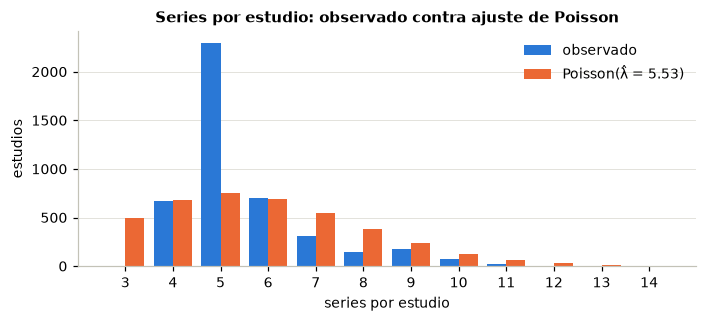

LRT bondad de ajuste: Λ = 3059.3, gl = 2, crítico = 5.99, p = 0.0e+00


In [9]:
x = se.groupby("StudyInstanceUID").size()
lam = x.mean()
print(f"λ̂ (MLE) = x̄ = {lam:.2f} | varianza muestral = {x.var():.2f} | índice de dispersión = {x.var() / lam:.2f}")

k = np.arange(x.min(), x.max() + 1)
obs = x.value_counts().reindex(k, fill_value=0)
esp = len(x) * stats.poisson.pmf(k, lam)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(k - 0.2, obs, width=0.4, color=AZUL, label="observado")
ax.bar(k + 0.2, esp, width=0.4, color=NARANJA, label=f"Poisson(λ̂ = {lam:.2f})")
ax.set_xticks(k); ax.set_xlabel("series por estudio"); ax.set_ylabel("estudios")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_title("Series por estudio: observado contra ajuste de Poisson")
plt.tight_layout(); plt.show()

# LRT de bondad de ajuste: H0 Poisson(λ̂) contra H1 multinomial libre, agrupando colas.
bins = [(-np.inf, 4), (5, 5), (6, 6), (7, np.inf)]
O = np.array([((x >= a) & (x <= b)).sum() for a, b in bins])
P = np.array([stats.poisson.cdf(b, lam) - stats.poisson.cdf(a - 1, lam) if np.isfinite(a) else stats.poisson.cdf(b, lam)
              for a, b in bins]); P[-1] = 1 - P[:-1].sum()
G = 2 * (O * np.log(O / (len(x) * P))).sum(); gl = len(bins) - 1 - 1
print(f"LRT bondad de ajuste: Λ = {G:.1f}, gl = {gl}, crítico = {stats.chi2.ppf(.95, gl):.2f}, p = {stats.chi2.sf(G, gl):.1e}")

**Interpretación.** La varianza es apenas un tercio de la media (subdispersión) y la prueba rechaza la Poisson con holgura: casi todos los estudios tienen 5 o 6 series. Tiene sentido, porque las series no llegan "al azar" como llamadas a un call center: las fija el protocolo del hospital (las 5 combinaciones de plano y secuencia). Es otro argumento para que el modelo reciba un número **fijo** de ranuras en lugar de una cantidad variable de series.

### 1.8 Inspección visual

Corte central de cada ranura para cuatro estudios gold, tomado del corpus ya preprocesado (cortes ordenados por posición física y recortados a 140 mm de anatomía, ver Fase 3).

In [ ]:
z = np.load(RES / "gold_slices.npz")
sl, ids, slots = z["slices"], z["ids"], z["slots"]
fig, axs = plt.subplots(len(ids), len(slots), figsize=(10, 2.25 * len(ids)))
for i, uid in enumerate(ids):
    pos = [ES[t] for t in T if gold.loc[uid, t] == 1]
    for j in range(len(slots)):
        ax = axs[i, j]; ax.imshow(sl[i, j], cmap="gray"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if i == 0: ax.set_title(str(slots[j]).replace("Sagittal", "Sagital"))
    axs[i, 0].set_ylabel(f"estudio {i + 1}", fontsize=9)
    axs[i, -1].text(1.05, 0.5, ", ".join(pos) if pos else "sin hallazgos", transform=axs[i, -1].transAxes,
                    va="center", fontsize=8, wrap=True)
plt.subplots_adjust(right=0.8, wspace=0.03, hspace=0.05); plt.show()

**Interpretación.** En las secuencias con supresión de grasa (FS) el líquido se ve blanco: el derrame y el edema óseo de una contusión destacan, y por eso esas ranuras pesan para derrame, sinovitis y contusión. Las secuencias sin supresión muestran mejor la anatomía (ligamentos, meniscos). Los cortes de un mismo estudio tienen orientación y escala consistentes gracias al recorte por milímetros; esto se verificó a ojo en más estudios antes de entrenar.

## Fase 2. Pseudo-etiquetas desde el reporte

Como no se pueden etiquetar a mano 4,349 estudios, se usan etiquetas producidas por modelos de lenguaje que leyeron cada reporte. Hay tres juegos públicos (CC0). Antes de confiar en ellos se **validan contra los 58 estudios gold**: si el reporte dice la verdad, la probabilidad que asigna el LLM debería ordenar bien a positivos y negativos.

In [11]:
L = DATA / "labels"
juegos = {"steven_v4": pd.read_csv(L / "stevenleehans/llm_labels_v4_blend.csv"),
          "steven_v2": pd.read_csv(L / "stevenleehans/llm_labels_v2.csv"),
          "steven_full": pd.read_csv(L / "stevenleehans/llm_labels_full.csv"),
          "pilkwang_v2": pd.read_csv(L / "pilkwang/report_labels_v2.csv")}
juegos = {k: v.set_index("StudyInstanceUID")[T] for k, v in juegos.items()}

auc_lbl = {}
for k, v in juegos.items():
    comun = gold.index.intersection(v.index)
    auc_lbl[k] = {t: roc_auc_score(gold.loc[comun, t], v.loc[comun, t]) for t in T}
    auc_lbl[k]["n gold"] = len(comun)
auc_lbl = pd.DataFrame(auc_lbl).rename(index=ES)
auc_lbl.loc["MACRO"] = auc_lbl.iloc[:12].mean()
display(auc_lbl.round(3).style.highlight_max(axis=1, subset=pd.IndexSlice[auc_lbl.index[:12].tolist() + ["MACRO"], :],
                                             props="font-weight:bold"))

,steven_v4,steven_v2,steven_full,pilkwang_v2
LCA,0.987000,0.993000,0.993000,0.997000
LCM,0.968000,0.964000,0.964000,0.976000
Menisco med.,0.948000,0.954000,0.954000,0.943000
Menisco lat.,0.879000,0.862000,0.862000,0.841000
OA medial,0.932000,0.931000,0.931000,0.908000
OA lateral,0.833000,0.830000,0.830000,0.789000
OA patelofem.,0.902000,0.901000,0.901000,0.891000
Derrame,0.877000,0.853000,0.853000,0.830000
Sinovitis,0.790000,0.790000,0.678000,0.694000
Q. Baker,0.944000,0.946000,0.946000,0.932000


**Interpretación.** `steven_v4` es el mejor juego (AUC macro 0.893) y es el que se usa. Sus etiquetas son muy buenas para LCA, LCM, menisco medial y quiste de Baker (0.94 a 0.99), y débiles para **sinovitis** y **fractura** (0.79), **OA lateral** (0.83) y **contusión** (0.86). El modelo de imagen aprende a imitar estas etiquetas, así que su calidad es un punto de partida importante (la Fase 4 mide cuánto se hereda).

¿Por qué son débiles? La siguiente tabla mide cuánta incertidumbre deja el LLM, como la fracción de estudios con etiqueta entre 0.3 y 0.7 (el LLM "no está seguro"), y compara la media de la etiqueta con la prevalencia gold.

,% incierto (0.3-0.7),AUC etiqueta vs gold,"media etiqueta (4,349)",prevalencia gold
Sinovitis,47.068,0.790,0.338,0.466
Menisco med.,15.176,0.948,0.460,0.448
Menisco lat.,11.497,0.879,0.223,0.397
Contusión,10.738,0.860,0.260,0.328
OA lateral,4.300,0.833,0.326,0.190
LCA,4.139,0.987,0.232,0.414
OA medial,2.598,0.932,0.407,0.259
LCM,2.368,0.968,0.179,0.155
OA patelofem.,1.862,0.902,0.483,0.362
Fractura,1.357,0.793,0.182,0.310


Correlación de Spearman entre incertidumbre y AUC de la etiqueta: -0.17 (p = 0.587)


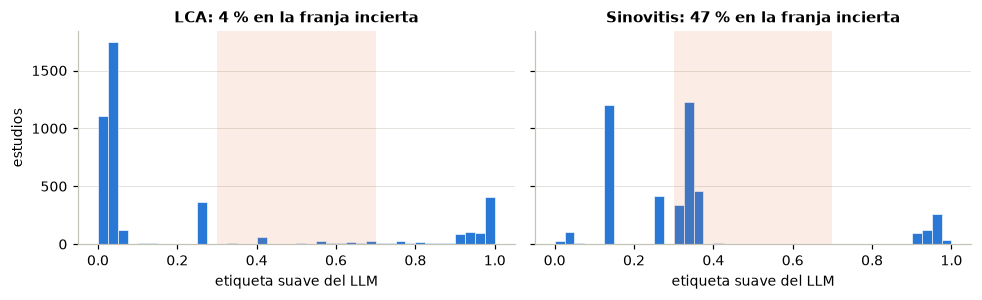

In [12]:
v4 = juegos["steven_v4"]
no_gold = v4.drop(gold.index, errors="ignore")
inc = ((no_gold > 0.3) & (no_gold < 0.7)).mean().rename(index=ES)
tabla = pd.DataFrame({"% incierto (0.3-0.7)": 100 * inc, "AUC etiqueta vs gold": auc_lbl.loc[inc.index, "steven_v4"],
                      "media etiqueta (4,349)": no_gold.mean().rename(index=ES), "prevalencia gold": p_hat.rename(index=ES)})
display(tabla.sort_values("% incierto (0.3-0.7)", ascending=False).round(3))
r_inc = stats.spearmanr(tabla["% incierto (0.3-0.7)"], tabla["AUC etiqueta vs gold"])
print(f"Correlación de Spearman entre incertidumbre y AUC de la etiqueta: {r_inc.statistic:.2f} (p = {r_inc.pvalue:.3f})")

fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, t in zip(axs, ["ACL", "Synovitis"]):
    ax.hist(no_gold[t], bins=40, range=(0, 1), color=AZUL, edgecolor="white", linewidth=0.4)
    ax.axvspan(0.3, 0.7, color=NARANJA, alpha=0.12, lw=0)
    ax.set_title(f"{ES[t]}: {100 * inc[ES[t]]:.0f} % en la franja incierta"); ax.set_xlabel("etiqueta suave del LLM")
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("estudios"); plt.tight_layout(); plt.show()

**Interpretación.** Hay dos tipos de error en las etiquetas, y conviene separarlos:

- **Etiqueta incierta.** El 47 % de las etiquetas de sinovitis cae en la franja incierta, contra 4 % en LCA: el reporte rara vez es tajante sobre la sinovitis (es un hallazgo sutil que muchos radiólogos no describen). Esto motivó el modelo v3 (Fase 3), que da menos peso a las etiquetas inciertas.
- **Etiqueta segura pero equivocada.** Fractura y OA lateral tienen AUC bajo con muy poca incertidumbre (1 y 4 %). Ahí el LLM no duda; probablemente el reporte omite el hallazgo o lo describe con otras palabras.

Por eso la correlación entre incertidumbre y AUC de la etiqueta es débil y no significativa ($\rho=-0.17$, $p=0.59$): la incertidumbre explica la sinovitis, no el resto.

La comparación de medias también muestra sesgo sistemático: la etiqueta **subestima** los hallazgos traumáticos (LCA 0.23 contra 0.41 en gold, fractura 0.18 contra 0.31) y **sobreestima** los degenerativos (OA medial 0.41 contra 0.26, quiste de Baker 0.36 contra 0.21). Parte puede ser que los 58 gold no representen a los 4,349 (la competencia avisa que las prevalencias cambian entre conjuntos), y parte, sesgo del LLM. Para el AUC no importa: un corrimiento en la escala no cambia el orden.

### 2.1 ¿Las etiquetas conservan la estructura multivariada?

Un buen juego de etiquetas debe reproducir no solo cada hallazgo por separado (las marginales) sino también cómo se acompañan (la matriz de correlación). Se compara $\mathbf R$ de los 58 gold con la matriz de correlación de las etiquetas suaves en los 4,349 estudios restantes.

Correlación entre los 66 coeficientes (gold vs LLM): r = 0.74, p = 1.2e-12
Distancia de Frobenius ||R_gold - R_llm||: 2.07


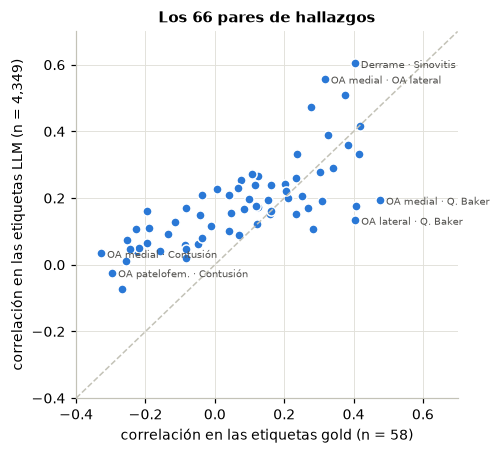

In [13]:
R_llm = no_gold.corr()
x_, y_ = R.values[iu], R_llm.values[iu]
r = stats.pearsonr(x_, y_)
print(f"Correlación entre los 66 coeficientes (gold vs LLM): r = {r.statistic:.2f}, p = {r.pvalue:.1e}")
print(f"Distancia de Frobenius ||R_gold - R_llm||: {np.linalg.norm(R.values - R_llm.values):.2f}")

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.axline((0, 0), slope=1, color="#c3c2b7", lw=1, ls="--")
ax.scatter(x_, y_, s=36, color=AZUL, edgecolor="white", linewidth=1)
sel = set(np.argsort(-y_)[:2]) | set(np.argsort(y_ - x_)[:2]) | set(np.argsort(x_)[:2])
for m, (i, j) in enumerate(zip(*iu)):
    if m in sel:
        ax.annotate(f"{ES[T[i]]} · {ES[T[j]]}", (R.values[i, j], R_llm.values[i, j]), fontsize=6.5,
                    xytext=(4, -3), textcoords="offset points", color="#52514e")
ax.set_xlabel("correlación en las etiquetas gold (n = 58)"); ax.set_ylabel("correlación en las etiquetas LLM (n = 4,349)")
ax.set_title("Los 66 pares de hallazgos"); ax.set_xlim(-0.4, 0.7); ax.set_ylim(-0.4, 0.7)
plt.tight_layout(); plt.show()

**Interpretación.** Las dos matrices se parecen ($r=0.74$ entre los 66 coeficientes): los pares que se acompañan en los datos reales también se acompañan en las etiquetas LLM, y el par más fuerte del LLM (derrame y sinovitis) es una de las familias de la sección 1.2. Pero la nube no está sobre la diagonal:

- Las correlaciones **negativas** del gold (degenerativo contra traumático) quedan cerca de 0 en el LLM: todos los puntos de la izquierda están por encima de la diagonal.
- Varios pares degenerativos (OA medial y quiste de Baker, OA lateral y quiste de Baker) quedan por debajo.

Una explicación probable es la forma de las etiquetas suaves: cuando el reporte no menciona un hallazgo, el LLM deja un valor intermedio en vez de 0, y esa "masa" intermedia compartida por todos los hallazgos empuja las covarianzas hacia un valor común. Aun así, la estructura positiva se conserva, y se aceptan las etiquetas `steven_v4` como verdad aproximada para entrenar.

## Fase 3. Modelo de imagen

### 3.1 Preprocesamiento

Los 265 GB del `archive.zip` original se leyeron directo del zip en una PC con GPU (RTX 3060), sin descomprimir. Para cada estudio:

1. Se eligen hasta 5 series, una por ranura (sagital FS, sagital no-FS, coronal FS, coronal no-FS, axial), con la distribución conjunta de la sección 1.6.
2. Los cortes se ordenan por posición física (`ImagePositionPatient` proyectada sobre la normal del plano), no por nombre de archivo.
3. Se conserva del 6 al 94 % de los cortes de cada serie y se toman 18, 14, 12, 8 y 12 cortes por ranura (64 en total).
4. Cada corte se recorta a 140 mm de anatomía (no a un número fijo de píxeles, porque la resolución va de 192 a 1024 px) y se lleva a 336 × 336, normalizado por percentiles de la serie.

Resultado: un arreglo de 4,407 × 64 × 336 × 336 (`uint8`), generado en 22 minutos con 4 procesos.

### 3.2 Arquitectura

Cada tres cortes vecinos forman los tres canales de una imagen (enfoque 2.5D). Una red convolucional-transformer preentrenada (CoAtNet, 384 px) extrae un vector de rasgos por ventana, y una capa de **atención por hallazgo** (multiple instance learning) pondera las ventanas: cada uno de los 12 hallazgos decide qué cortes mirar. El extractor es compartido entre los 12 hallazgos, como sugiere la dependencia de la sección 1.4.

### 3.3 El entrenamiento es máxima verosimilitud

La salida del modelo para el estudio $i$ y hallazgo $k$ es $\hat p_{ik}=\sigma(z_{ik})$. Si la etiqueta fuera binaria, la log-verosimilitud Bernoulli de la muestra sería $\ell=\sum_{i,k}\left[y_{ik}\ln\hat p_{ik}+(1-y_{ik})\ln(1-\hat p_{ik})\right]$, y **minimizar la entropía cruzada binaria (BCE) es exactamente maximizar esa verosimilitud**. Con etiquetas suaves $q_{ik}\in[0,1]$ la pérdida es la misma fórmula con $q$ en lugar de $y$; derivando,

$$\frac{\partial}{\partial \hat p}\Big[-q\ln\hat p-(1-q)\ln(1-\hat p)\Big]=0\ \Rightarrow\ \hat p=q,$$

así que el óptimo es reproducir la probabilidad que dio el LLM. Dos ajustes del entrenador:

- **Peso a positivos** $w^{+}_k=\min\!\left(\max\!\left(\tfrac{1-\bar q_k}{\bar q_k},1\right),10\right)$, para que los hallazgos poco frecuentes no queden ignorados.
- **Verosimilitud ponderada por confianza (modelo v3)**: cada término se multiplica por $w_{ik}=\max(0.25,\,2|q_{ik}-0.5|)$, que vale 1 cuando el LLM está seguro y baja hasta 0.25 cuando duda (sección 2). Es un estimador de máxima verosimilitud ponderada.

### 3.4 Curvas de entrenamiento

Cada epoch recorre los 4,349 estudios sin etiqueta gold (unos 50 minutos) y al cerrar se mide el AUC macro contra los 58 gold. v1 usó el corpus público de 44 cortes; v2, el corpus propio de 64 cortes. v1 se detuvo en el epoch 4 por un reinicio de la PC.

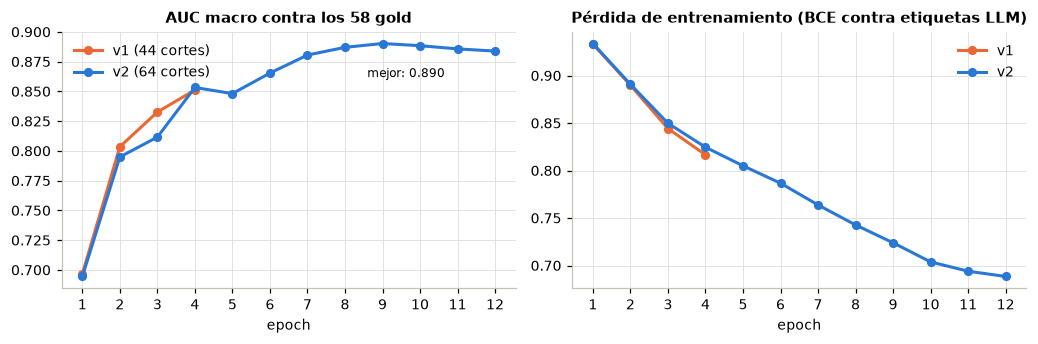

ep,1,2,3,4,5,6,7,8,9,10,11,12
loss,0.934,0.891,0.850,0.825,0.805,0.787,0.764,0.743,0.724,0.704,0.694,0.688
gold_auc,0.695,0.795,0.812,0.853,0.848,0.865,0.881,0.887,0.890,0.888,0.886,0.884


In [14]:
hist = {v: pd.DataFrame(json.load(open(RES / f"gold/raptor_ft_coatnet_{v}.json"))["hist"]) for v in ["v1", "v2"]}
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2))
for (v, h), col in zip(hist.items(), [NARANJA, AZUL]):
    axs[0].plot(h.ep + 1, h.gold_auc, "-o", color=col, lw=2, ms=5, label=f"{v} ({'44' if v == 'v1' else '64'} cortes)")
    axs[1].plot(h.ep + 1, h.loss, "-o", color=col, lw=2, ms=5, label=v)
b = hist["v2"].gold_auc.idxmax()
axs[0].annotate(f"mejor: {hist['v2'].gold_auc[b]:.3f}", (b + 1, hist["v2"].gold_auc[b]), xytext=(-10, -22),
                textcoords="offset points", fontsize=8)
axs[0].set_title("AUC macro contra los 58 gold"); axs[0].set_xlabel("epoch"); axs[0].legend(frameon=False)
axs[1].set_title("Pérdida de entrenamiento (BCE contra etiquetas LLM)"); axs[1].set_xlabel("epoch")
axs[1].legend(frameon=False)
for ax in axs: ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
display(hist["v2"].assign(ep=lambda d: d.ep + 1).set_index("ep").T.round(3))

**Interpretación.** Las curvas de v1 y v2 casi se encimaron en los epochs que ambos alcanzaron, y v2 siguió subiendo hasta el epoch 9 (0.890). Después la pérdida de entrenamiento sigue bajando pero el AUC gold **baja**: el modelo empieza a memorizar el ruido de las etiquetas LLM en vez de lo que generaliza a la etiqueta real. Es sobreajuste clásico, y la respuesta fue no quedarse con el último epoch sino promediar los pesos de los epochs 8 a 10 (SWA, *stochastic weight averaging*), que dio 0.8916.

## Fase 4. Validación: ¿cuánto se puede confiar en 58 estudios?

El AUC de cada hallazgo se calcula sobre 58 estudios, con apenas 9 positivos en el caso del LCM. Para dar un intervalo de confianza se usa **bootstrap**: se remuestrean los 58 estudios con reemplazo (el estudio es la unidad, así se conserva la dependencia entre los 12 hallazgos de un mismo paciente), se recalcula el AUC y se toman los percentiles 2.5 y 97.5 de 2,000 réplicas. Para comparar dos modelos se usa **bootstrap pareado**: en cada réplica ambos se evalúan sobre los mismos estudios y se guarda la diferencia.

AUC macro v2 SWA ep8-10: 0.8916  IC95 bootstrap [0.856, 0.922]


,AUC,IC95_inf,IC95_sup,positivos,AUC etiqueta LLM
OA lateral,0.789,0.583,0.964,11,0.833
Sinovitis,0.798,0.678,0.901,27,0.790
OA patelofem.,0.812,0.682,0.922,21,0.902
Menisco lat.,0.820,0.702,0.923,23,0.879
Fractura,0.840,0.694,0.958,18,0.793
LCM,0.896,0.785,0.979,9,0.968
Derrame,0.913,0.824,0.977,35,0.877
LCA,0.945,0.864,0.996,24,0.987
Menisco med.,0.960,0.907,0.994,26,0.948
Contusión,0.961,0.912,0.995,19,0.860


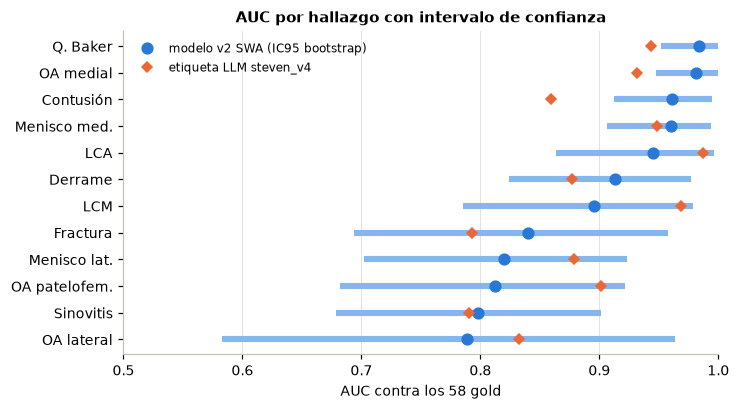

Spearman entre AUC del modelo y AUC de su etiqueta: 0.53 (p = 0.075)


In [15]:
def cargar(nombre):
    z = np.load(RES / f"gold/raptor_gold_{nombre}.npz")
    return pd.DataFrame(z["pred"], index=z["ids"], columns=T), pd.DataFrame(z["truth"], index=z["ids"], columns=T)

modelos = {"v2 SWA ep8-10": "coatnet_v2_swa", "v2 ep9 (mejor)": "coatnet_v2", "v2 ep8": "coatnet_v2_ep7",
           "v2 ep10": "coatnet_v2_ep9", "v2 promedio ep8-10": "coatnet_v2_epens", "v1 ep4": "coatnet_v1"}
P = {k: cargar(v)[0] for k, v in modelos.items()}
Y = cargar("coatnet_v2_swa")[1].astype(int)
assert (Y.values == gold.loc[Y.index].values).all()

def aucs(y, p):
    return np.array([roc_auc_score(y[:, k], p[:, k]) if 0 < y[:, k].sum() < len(y) else np.nan for k in range(12)])

rng = np.random.default_rng(0)
B = 2000
idx = rng.integers(0, len(Y), size=(B, len(Y)))
y = Y.values
boot = {k: np.array([aucs(y[b], P[k].values[b]) for b in idx]) for k in P}
punto = {k: aucs(y, P[k].values) for k in P}

ref = "v2 SWA ep8-10"
ic = pd.DataFrame({"AUC": punto[ref], "IC95_inf": np.nanpercentile(boot[ref], 2.5, 0),
                   "IC95_sup": np.nanpercentile(boot[ref], 97.5, 0), "positivos": y.sum(0),
                   "AUC etiqueta LLM": auc_lbl["steven_v4"].iloc[:12].values}, index=[ES[t] for t in T])
mac = np.nanmean(boot[ref], 1)
print(f"AUC macro {ref}: {np.mean(punto[ref]):.4f}  IC95 bootstrap [{np.percentile(mac, 2.5):.3f}, {np.percentile(mac, 97.5):.3f}]")
ic = ic.sort_values("AUC")
display(ic.round(3))

fig, ax = plt.subplots(figsize=(6.8, 3.8))
yy = np.arange(12)
ax.hlines(yy, ic.IC95_inf, ic.IC95_sup, color="#86b6ef", lw=4)
ax.plot(ic.AUC, yy, "o", color=AZUL, ms=7, label="modelo v2 SWA (IC95 bootstrap)")
ax.plot(ic["AUC etiqueta LLM"], yy, "D", color=NARANJA, ms=5, label="etiqueta LLM steven_v4")
ax.set_yticks(yy, ic.index); ax.set_xlim(0.5, 1.0); ax.axvline(0.5, color="#c3c2b7", lw=1)
ax.set_xlabel("AUC contra los 58 gold"); ax.legend(frameon=False, loc="upper left", fontsize=8)
ax.set_title("AUC por hallazgo con intervalo de confianza"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
rho = stats.spearmanr(ic.AUC, ic["AUC etiqueta LLM"])
print(f"Spearman entre AUC del modelo y AUC de su etiqueta: {rho.statistic:.2f} (p = {rho.pvalue:.3f})")

In [16]:
filas = []
for k in P:
    if k == ref: continue
    d = np.nanmean(boot[ref], 1) - np.nanmean(boot[k], 1)
    filas.append((k, np.mean(punto[ref]) - np.mean(punto[k]), np.percentile(d, 2.5), np.percentile(d, 97.5),
                  (d <= 0).mean()))
comp = pd.DataFrame(filas, columns=["comparado contra", "diferencia AUC macro", "IC95_inf", "IC95_sup",
                                    "P(bootstrap) de que no mejore"])
display(comp.round(4))

,comparado contra,diferencia AUC macro,IC95_inf,IC95_sup,P(bootstrap) de que no mejore
0,v2 ep9 (mejor),0.0014,-0.0049,0.0071,0.3185
1,v2 ep8,0.0046,-0.0045,0.0137,0.1610
2,v2 ep10,0.0032,-0.0037,0.0109,0.1860
3,v2 promedio ep8-10,0.0001,-0.0034,0.0041,0.5005
4,v1 ep4,0.0404,0.0155,0.0655,0.0010


**Interpretación.**

- El AUC macro de 0.892 tiene un intervalo de [0.856, 0.922], unos ±0.03. Por hallazgo los intervalos son mucho más anchos: el de OA lateral va de 0.58 a 0.96, porque solo hay 11 positivos. El orden entre hallazgos parecidos no es confiable.
- Contra las otras variantes de v2 (epochs vecinos, promedio de predicciones) las diferencias son de milésimas y sus intervalos incluyen al 0: **no se distinguen estadísticamente**. Elegir SWA fue una decisión razonable (es la práctica de la comunidad y reduce varianza), no una mejora medida. Contra v1 (4 epochs) la diferencia de 0.040 sí es significativa: su intervalo, [0.016, 0.066], no incluye al 0.
- El modelo **no** es una simple copia de su etiqueta. La correlación entre el AUC del modelo y el de la etiqueta es moderada y no significativa ($\rho=0.53$, $p=0.075$), y en varios hallazgos el modelo supera a la etiqueta con la que se entrenó: contusión (0.96 contra 0.86), fractura (0.84 contra 0.79), OA medial, quiste de Baker y derrame. Una explicación: el modelo ve 4,349 estudios y aprende el patrón de imagen común a los que el LLM marca como positivos. Si los errores de la etiqueta son ruido sin relación con la imagen, se promedian y se cancelan, como en la ley de los grandes números. Lo que no se cancela es el error sistemático, y ahí están las debilidades del modelo: OA lateral, sinovitis, OA patelofemoral y menisco lateral.
- Sesgo a tener en cuenta: los 58 gold no se usaron para entrenar, pero sí para elegir el epoch. El AUC reportado es ligeramente optimista; el leaderboard de Kaggle (~1,300 estudios nuevos) es la validación independiente.

## Fase 5. Inferencia como code competition

El envío no es un archivo sino un notebook de Kaggle que corre sobre los ~1,300 estudios ocultos con estas reglas: sin internet, máximo 9 horas en una GPU T4, y la salida debe llamarse `submission.csv`. Lo que hace el notebook de inferencia (`kaggle/infer_v2/`):

1. Lee los DICOM del test con el mismo preprocesamiento de la Fase 3 (ranuras, orden físico, recorte a 140 mm). Un lector tolerante devuelve ranuras vacías ante un DICOM roto: en la competencia hubo envíos ajenos que fallaron completos por un solo estudio ilegible.
2. Carga los pesos del modelo v2 SWA desde un dataset privado de Kaggle (`hctorheredia/kad-knee-weights`).
3. Predice con media precisión (fp16, la T4 no soporta bf16) y promedia con el espejo horizontal (TTA).

Con los 3 estudios de ejemplo corrió en 39 segundos, sin fallos.

## Fase 6. Envíos y combinación por rangos

In [17]:
subs = pd.read_csv(RES / "submissions.csv")
display(subs.fillna("pendiente"))

,submission_id,fecha,descripcion,auc_gold,score_publico
0,57232135,2026-10-15,"KAD v2: CoAtNet-384 2.5D + MIL, SWA de los epo...",0.8916,0.919
1,57240482,2026-10-15,Combinación por rangos: público R7 0.957 + KAD...,pendiente,pendiente
2,57240695,2026-10-15,Control: público R7 0.957 sin KAD (peso 0),pendiente,pendiente


El modelo propio sacó **0.919** en el leaderboard público, por encima de su AUC gold (0.892) y del notebook público con la misma receta (0.914). Que el público suba respecto a gold es consistente con que el test tenga otras prevalencias y mucho más tamaño; la diferencia contra el notebook público (0.005) está dentro del ruido de la sección 4.

Los mejores notebooks públicos (~0.957) combinan varios modelos. Como el AUC solo depende del orden, la forma natural de combinar es por **rangos**: para cada hallazgo, cada modelo $m$ convierte sus puntuaciones en rangos normalizados $r_m(i)=\operatorname{rank}(s_{mi})/N$ y se promedian con pesos,

$$s_i^{\text{final}}=\sum_m w_m\,r_m(i),\qquad \sum_m w_m=1.$$

Promediar probabilidades directamente mezclaría escalas distintas (un modelo puede dar 0.9 a lo que otro da 0.6 con el mismo orden); el rango elimina esa diferencia, y cualquier transformación monótona posterior deja el AUC igual. Combinar ayuda cuando los errores de los modelos no están perfectamente correlacionados, por la misma razón que la varianza de un promedio $\operatorname{Var}\big(\tfrac{X_1+X_2}{2}\big)=\tfrac14\left(\sigma_1^2+\sigma_2^2+2\sigma_{12}\right)$ baja más mientras menor sea la covarianza $\sigma_{12}$.

Para medir si el modelo propio aporta se mandaron dos envíos con el mismo notebook público: uno con peso 0.15 para el modelo propio y otro de control con peso 0.

## Conclusiones

1. **El problema es un vector Bernoulli dependiente.** La matriz de correlación de los 12 hallazgos tiene estructura clara (familias degenerativa y traumática, con correlación negativa entre ellas) y la prueba de razón de verosimilitudes rechaza la independencia en muchos más pares de los esperados por azar. Por eso conviene un solo modelo con extractor compartido.
2. **Las etiquetas definen el techo, pero el modelo no las copia.** Con 58 estudios gold, el entrenamiento depende de etiquetas derivadas del reporte por un LLM. Las mejores (AUC 0.893) conservan la estructura positiva de la matriz de correlación real ($r=0.74$), aunque aplanan las correlaciones negativas. Tienen dos tipos de error: incertidumbre (sinovitis) y error seguro (fractura, OA lateral). El modelo de imagen promedia el ruido de miles de estudios y supera a su etiqueta en varios hallazgos (contusión 0.96 contra 0.86); donde el error es sistemático, lo hereda.
3. **El entrenamiento es máxima verosimilitud** de una Bernoulli con etiquetas suaves; la variante ponderada por confianza (v3) es máxima verosimilitud ponderada.
4. **58 estudios son una regla corta.** El intervalo bootstrap del AUC macro mide ±0.03, y las variantes cercanas del modelo no se distinguen estadísticamente. Las decisiones finas se validan en el leaderboard, no en gold.
5. **Resultado.** El modelo propio sacó 0.919 en el leaderboard público, a la par de la receta pública de la que parte. La combinación por rangos con modelos públicos se documenta en el notebook 2.

## Referencias

- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29-36.
- Johnson, R. A., & Wichern, D. W. (2007). *Applied multivariate statistical analysis* (6.ª ed.). Pearson.
- Izmailov, P., Podoprikhin, D., Garipov, T., Vetrov, D., & Wilson, A. G. (2018). Averaging weights leads to wider optima and better generalization. *UAI 2018*.
- Dai, Z., Liu, H., Le, Q. V., & Tan, M. (2021). CoAtNet: Marrying convolution and attention for all data sizes. *NeurIPS 2021*.
- dreaddevelopment. (2026). *Knee MRI: training the twelve-finding model* y *Knee MRI: twelve findings from a single model* [Notebooks de Kaggle, Apache 2.0].
- stevenleehans. (2026). *RSNA knee LLM report labels* [Dataset de Kaggle, CC0].
- RSNA. (2026). *RSNA Knee Abnormality Detection* [Competencia de Kaggle]. https://www.kaggle.com/competitions/rsna-knee-abnormality-detection